In [49]:
import os
from pathlib import Path
from typing import Literal, Optional, List
import yaml

import numpy as np
import math
import uproot as uproot
import pickle
import pandas as pd
import awkward as ak
from dataclasses import dataclass, field

import matplotlib.pyplot as plt
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white"})
import matplotlib.colors
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import ticker
from matplotlib.ticker import (AutoMinorLocator, MultipleLocator)
from matplotlib import gridspec
import seaborn as sns

os.environ["PROJECT_PATH"] = "/home/syebes/lambda-ana"
project_path = Path(os.environ["PROJECT_PATH"])
sys.path.append(str(project_path))

# My imports
from src.driver import AnalysisDriver
import src.branches as branches
from src.cuts import CutConfig, create_cut

# Load files

In [2]:
lambda_file = 'root://fndcadoor.fnal.gov:1094/pnfs/fnal.gov/usr/sbnd//scratch/users/syebes/v10_14_02_04/ccqeLambda/OriginsAna/fransOutput_opPandora.root'
frans_tdir = "FRANSProducer/fransTree"

lambda_tree = uproot.open(lambda_file)[frans_tdir]

In [3]:
max_entry = None
indices =['run_id', 'subrun_id', 'event_id', 'slice_id']

lambda_df = pd.DataFrame(lambda_tree.arrays(branches.frans, library="np", entry_stop=max_entry))
lambda_df.set_index(indices, inplace=True)

# Michel tagging column

In [4]:
'''
df["michel_final_score"] = np.where(
    df["michel_score"] == -1,
    2,
    df["michel_score"]
)'''

lambda_df["michel_final_score"] = np.where(
    ~lambda_df["michel_vars_computed"],
    2,
    lambda_df["michel_score"]
)

# Preselection

In [5]:
preselected_mask = lambda_df.pre_pass

pre_df = lambda_df[preselected_mask]

# Selection

import importlib
import src

importlib.reload(src.driver)
importlib.reload(src.plotter)
importlib.reload(src.frans_branches)
importlib.reload(src.cuts)
from src.driver import AnalysisDriver
from src.frans_branches import branches
from src.cuts import CutConfig, create_cut

In [6]:
with open("../../config/cuts_config.yaml", "r") as f:
    config = yaml.safe_load(f)


cuts_config = []
for cut_cfg in config['frans_cuts'].values():
    cfg = CutConfig(
        cut = create_cut(cut_cfg['cut']),
        **{k: v for k, v in cut_cfg.items() if k != "cut"}
    )

    cuts_config.append(cfg)

In [7]:
driver = AnalysisDriver(pre_df, cuts_config)

In [8]:
#driver.plot_cuts()
#driver.get_cuts_performance(**config['initial_amounts'])
final_df = driver.get_final_df()

final_df.index = final_df.index.droplevel(-1)
signal_selected_indices = np.array(final_df[final_df.is_lambda_signal].index.to_list())
len(signal_selected_indices)

3062

In [9]:
final_df.columns.to_list()

['file_name',
 'gen_index',
 'nu_pdg',
 'nu_int_mode',
 'nu_int_type',
 'nu_cc_nc',
 'gen_id',
 'gen_status_code',
 'gen_mother',
 'gen_pdg',
 'gen_mass',
 'gen_e0',
 'gen_start_x',
 'gen_start_y',
 'gen_start_z',
 'gen_p0_x',
 'gen_p0_y',
 'gen_p0_z',
 'n_protons',
 'n_neutrons',
 'n_pi0',
 'n_pip',
 'n_pim',
 'n_mup',
 'n_mum',
 'n_ep',
 'n_em',
 'n_lambda',
 'n_sigma0',
 'n_sigmap',
 'n_sigmam',
 'n_hyperon',
 'true_gap',
 'has_lambda',
 'has_lambda_v',
 'is_lambda_signal',
 'slc_purity',
 'slc_completeness',
 'pre_is_clear_cosmic',
 'pre_nu_score',
 'pre_bcfm_score',
 'pre_is_fiducial',
 'pre_n_prim_pfps',
 'pre_n_prim_trks',
 'pre_n_prim_shwrs',
 'pre_n_trks_exit',
 'pre_max_gap',
 'pre_pass',
 'frans_n_origins',
 'frans_n_origins_mult1',
 'frans_n_origins_mult2',
 'frans_n_origins_gt3',
 'frans_n_origins_pair_one_two',
 'frans_n_unassoc_origins',
 'frans_n_unassoc_origins_mult1',
 'frans_n_unassoc_origins_mult2',
 'frans_n_unassoc_origins_mult3',
 'frans_succeed',
 'frans_n_angle

# Load FRANS PID tree

In [10]:
pid_branches = branches.frans_pid + branches.pid_extra

In [11]:
pid_tdir = "lambdaPidPandoraAna/CalorimetryTree"

lambda_pid_tree = uproot.open(lambda_file)[pid_tdir]
pid_arr = lambda_pid_tree.arrays(pid_branches, library="ak", entry_stop=max_entry)

In [12]:
arr_indices = np.array(ak.zip([
    pid_arr.RunID,
    pid_arr.SubRunID,
    pid_arr.EventID,
]).to_list())

signal_set = set(map(tuple, signal_selected_indices))

pid_sel_signal_mask = np.array([
    tuple(row) in signal_set
    for row in arr_indices
])

s_pid_arr = pid_arr[pid_sel_signal_mask]
len(s_pid_arr)

3062

## PID cut

In [13]:
s_pid_arr['pid_cut'] = (s_pid_arr.NTracksHI >=1) & (s_pid_arr.NTracksLI >=1)

In [15]:
n_signal = len(s_pid_arr)
n_pass_pid = sum(s_pid_arr.pid_cut)
n_not_pass_pid = sum(~s_pid_arr.pid_cut)

print(f'Signal passing PID cut: {n_pass_pid} ({100.*n_pass_pid/n_signal:.2f}%)')
print(f'Signal NOT passing PID cut: {n_not_pass_pid} ({100.*n_not_pass_pid/n_signal:.2f}%)')

Signal passing PID cut: 758 (24.76%)
Signal NOT passing PID cut: 2304 (75.24%)


## Pfp exploration

In [16]:
s_pid_arr.fields

['RunID',
 'SubRunID',
 'EventID',
 'NTracksHI',
 'NTracksLI',
 'InvariantMass',
 'slc_pfp_id',
 'slc_pfp_mother',
 'slc_pfp_is_primary',
 'slc_pfp_track_score',
 'slc_pfp_track_length',
 'slc_pfp_track_theta',
 'slc_pfp_track_phi',
 'slc_pfp_track_start_x',
 'slc_pfp_track_start_y',
 'slc_pfp_track_start_z',
 'slc_pfp_track_end_x',
 'slc_pfp_track_end_y',
 'slc_pfp_track_end_z',
 'slc_pfp_track_dir_x',
 'slc_pfp_track_dir_y',
 'slc_pfp_track_dir_z',
 'slc_pfp_track_kin_energy',
 'slc_pfp_chi2_muon',
 'slc_pfp_chi2_proton',
 'slc_pfp_chi2_pion',
 'slc_pfp_comp',
 'slc_pfp_pur',
 'slc_pfp_true_id',
 'slc_pfp_true_pdg',
 'slc_pfp_true_mother',
 'slc_pfp_true_start_x',
 'slc_pfp_true_start_y',
 'slc_pfp_true_start_z',
 'slc_pfp_true_end_x',
 'slc_pfp_true_end_y',
 'slc_pfp_true_end_z',
 'slc_pfp_true_mass',
 'slc_pfp_true_e0',
 'slc_pfp_true_ef',
 'slc_pfp_true_tl',
 'slc_pfp_true_p0_x',
 'slc_pfp_true_p0_y',
 'slc_pfp_true_p0_z',
 'slc_pfp_true_pf_x',
 'slc_pfp_true_pf_y',
 'slc_pfp_true

Signal with more than 2 pfps: 3029 (98.92%)


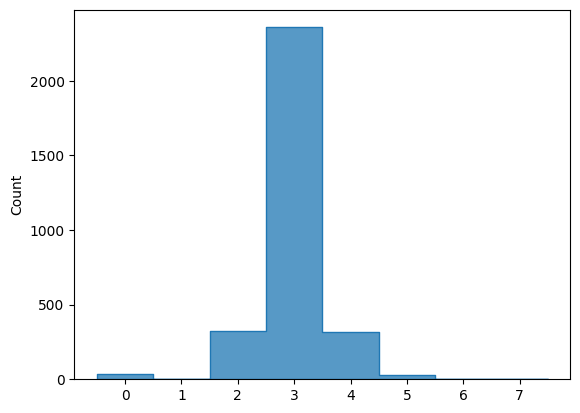

In [44]:
valid_pfp = ((s_pid_arr.slc_pfp_chi2_proton > 0)
            & (s_pid_arr.slc_pfp_chi2_pion > 0))

n_pfp = ak.num(s_pid_arr.slc_pfp_id, axis=1)
#n_pfp = ak.num(s_pid_arr.slc_pfp_id[valid_pfp], axis=1)

bins = np.arange(0,6,1)
sns.histplot(n_pfp,
             bins=bins, 
             discrete=True,
             element="step",)

n_get_2 = sum(n_pfp >= 2)
print(f'Signal with more than 2 pfps: {n_get_2} ({100.*n_get_2/n_signal:.2f}%)')

In [48]:
n_pfp_mask = (n_pfp > 2)

s_pid_arr[n_pfp_mask].slc_pfp_chi2_pion

<Array [[-999, 1.65, 43.4], ..., [-999, ..., 31.3]] type='2705 * var * float64'>

In [33]:
proton_mask = (s_pid_arr.slc_pfp_true_pdg == 2212)
pion_mask = (s_pid_arr.slc_pfp_true_pdg == -211)

proton_chi2p = ak.flatten(s_pid_arr.slc_pfp_chi2_proton[valid_pfp & proton_mask])
proton_chi2pi = ak.flatten(s_pid_arr.slc_pfp_chi2_pion[valid_pfp & proton_mask])
pion_chi2p = ak.flatten(s_pid_arr.slc_pfp_chi2_proton[valid_pfp & pion_mask])
pion_chi2pi = ak.flatten(s_pid_arr.slc_pfp_chi2_pion[valid_pfp & pion_mask])

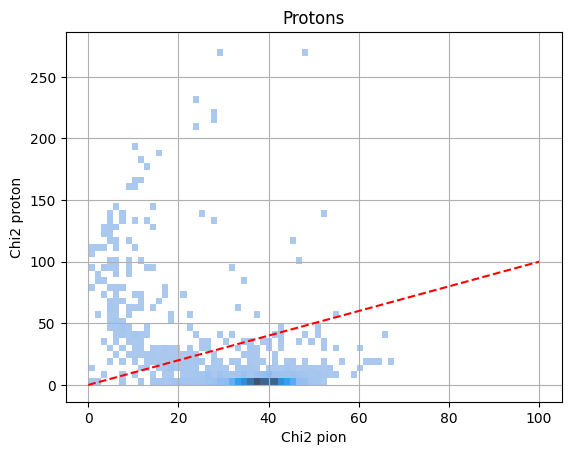

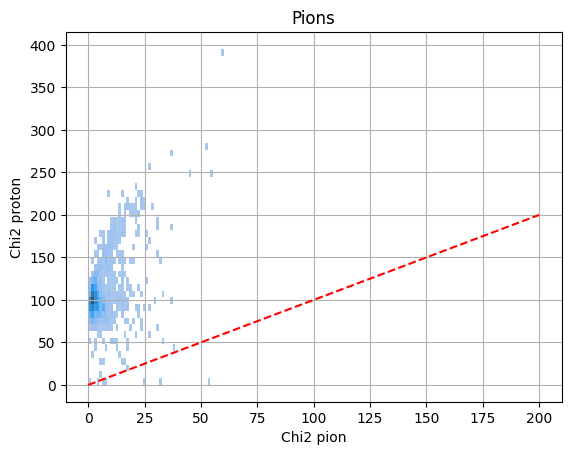

In [30]:
sns.histplot(
    x=proton_chi2pi,
    y=proton_chi2p,
    bins=50,)
plt.grid(True)
plt.title('Protons')
plt.xlabel('Chi2 pion')
plt.ylabel('Chi2 proton')
plt.plot([0, 100], [0, 100], "--", c='red')
plt.show()

plt.figure()
sns.histplot(
    x=pion_chi2pi,
    y=pion_chi2p,
    bins=50,)
plt.grid(True)
plt.title('Pions')
plt.xlabel('Chi2 pion')
plt.ylabel('Chi2 proton')
plt.plot([0, 200], [0, 200], "--", c='red')
plt.show()

In [31]:
n_pion = len(pion_chi2pi)
n_proton = len(proton_chi2pi)

n_reco_pion = sum(pion_chi2pi < pion_chi2p)
n_reco_proton = sum(proton_chi2pi > proton_chi2p)

print(f'True protons reco as protons: {n_reco_proton}/{n_proton} ({100.*n_reco_proton/n_proton:.2f}%)')
print(f'True pions reco as pions: {n_reco_pion}/{n_pion} ({100.*n_reco_pion/n_pion:.2f}%)')

True protons reco as protons: 1654/1865 (88.69%)
True pions reco as pions: 1222/1229 (99.43%)


In [21]:
def get_proton_variable(arr, var, mask):
    filtered_arr = s_pid_arr[var][mask]
    cleaning_mask = ak.any(mask, axis=1)
    return ak.flatten(filtered_arr[cleaning_mask])

Text(0.5, 0, 'No inelastic proton track length [cm]')

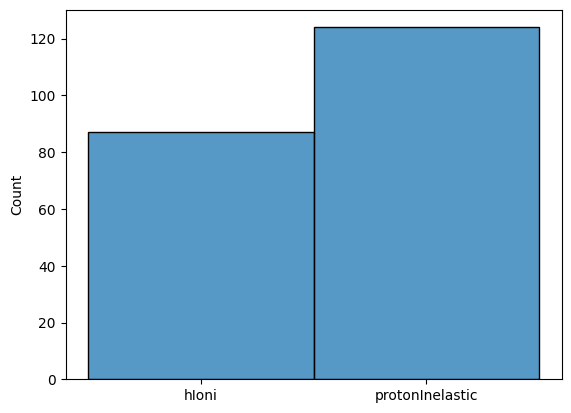

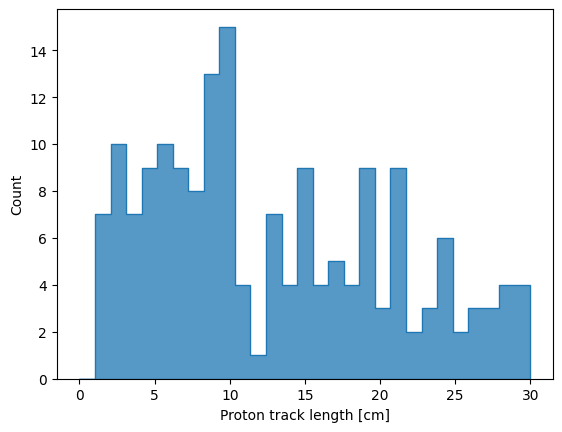

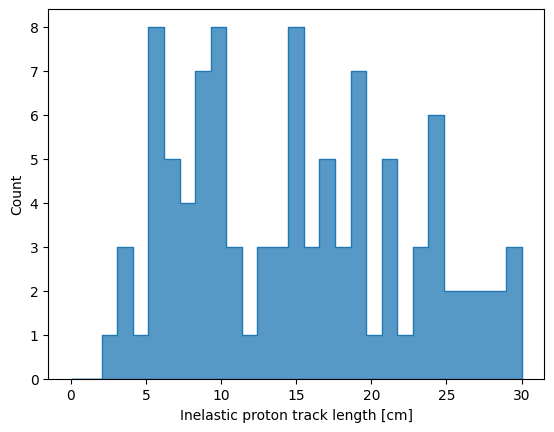

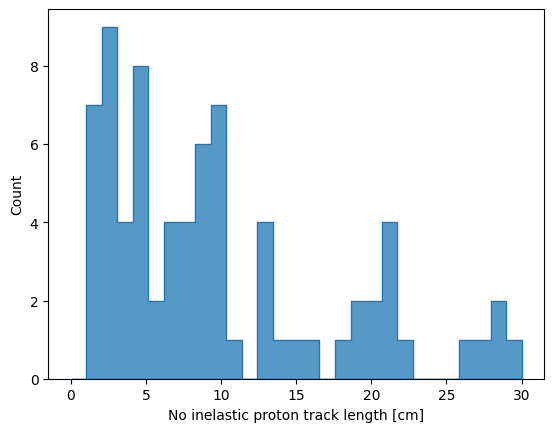

In [22]:
wrong_protons = (s_pid_arr.slc_pfp_chi2_proton) > (s_pid_arr.slc_pfp_chi2_pion)
ine_mask = (s_pid_arr.slc_pfp_true_end_process == 'protonInelastic')

wr_p_endp = get_proton_variable(s_pid_arr, 'slc_pfp_true_end_process', valid_pfp & proton_mask & wrong_protons)
wr_p_tl = get_proton_variable(s_pid_arr, 'slc_pfp_true_tl', valid_pfp & proton_mask & wrong_protons)

wr_ine_p_tl = get_proton_variable(s_pid_arr, 'slc_pfp_true_tl', valid_pfp & proton_mask & wrong_protons & ine_mask)
wr_noine_p_tl = get_proton_variable(s_pid_arr, 'slc_pfp_true_tl', valid_pfp & proton_mask & wrong_protons & ~ine_mask)

sns.histplot(wr_p_endp)

plt.figure()
sns.histplot(wr_p_tl,
            bins=np.linspace(0,30,30),
            element='step')
plt.xlabel('Proton track length [cm]')

plt.figure()
sns.histplot(wr_ine_p_tl,
            bins=np.linspace(0,30,30),
            element='step')
plt.xlabel('Inelastic proton track length [cm]')

plt.figure()
sns.histplot(wr_noine_p_tl,
            bins=np.linspace(0,30,30),
            element='step')
plt.xlabel('No inelastic proton track length [cm]')

NameError: name 'slc_pfp_true_tl' is not defined

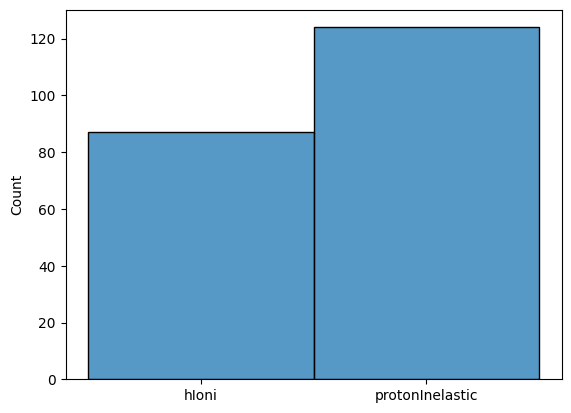

In [23]:

wrong_protons = (s_pid_arr.slc_pfp_chi2_proton) > (s_pid_arr.slc_pfp_chi2_pion)

arr = s_pid_arr.slc_pfp_true_end_process[valid_pfp & proton_mask & wrong_protons]
mask = ak.any(valid_pfp & proton_mask & wrong_protons, axis=1)

sns.histplot(ak.flatten(arr[mask]))
#hIoni is not inelastic proton

slc_pfp_true_tl

In [ ]:
wrong_protons

### New cut?

In [24]:
pfp_chi2p = s_pid_arr.slc_pfp_chi2_proton#[valid_pfp]
pfp_chi2pi = s_pid_arr.slc_pfp_chi2_pion#[valid_pfp]
pfp_chi2muon = s_pid_arr.slc_pfp_chi2_muon#[valid_pfp]

pfp_chi2_li = (pfp_chi2pi + pfp_chi2muon)/2

In [25]:
pid_cut = ak.any(pfp_chi2pi < pfp_chi2p, axis=1) & ak.any(pfp_chi2pi > pfp_chi2p, axis=1)
pid_cut_original = ak.any(pfp_chi2_li < pfp_chi2p, axis=1) & ak.any(pfp_chi2_li > pfp_chi2p, axis=1)

In [26]:
n_signal_pid_cut = sum(pid_cut)
n_signal_pid_cut_original = sum(pid_cut_original)

print(f'Signal passing new pid cut: {n_signal_pid_cut} ({100.*n_signal_pid_cut/n_signal:.2f}%)')
print(f'Signal passing new pid cut: {n_signal_pid_cut_original} ({100.*n_signal_pid_cut_original/n_signal:.2f}%)')

Signal passing new pid cut: 743 (24.27%)
Signal passing new pid cut: 744 (24.30%)


In [ ]:
print(sum(ak.any(pfp_chi2_li < pfp_chi2p, axis=1)))
print(sum(s_pid_arr.NTracksLI >= 1))

In [ ]:
print(sum(ak.any(pfp_chi2_li > pfp_chi2p, axis=1)))
print(sum(s_pid_arr.NTracksHI >= 1))